In [ ]:
import pandas as pd

df = pd.read_excel("/content/Customer_Segmentation_Clustering/Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# Check dataset information
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check number of unique customers
print("\nUnique Customers:")
print(df["CustomerID"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Unique Customers:
4372


In [ ]:
# Remove missing customer IDs
df = df.dropna(subset=["CustomerID"])

# Create total spending column
df["TotalSpend"] = df["Quantity"] * df["UnitPrice"]

# Create customer features
customer_df = df.groupby("CustomerID").agg({
    "TotalSpend": "sum",
    "InvoiceNo": "nunique",
    "Quantity": "sum"
})

# Rename columns
customer_df.columns = [
    "Total_Spend",
    "Number_of_Purchases",
    "Total_Items"
]

# View customer data
customer_df.head()

,Total_Spend,Number_of_Purchases,Total_Items
CustomerID,,,
12346.0,0.00,2,0
12347.0,4310.00,7,2458
12348.0,1797.24,4,2341
12349.0,1757.55,1,631
12350.0,334.40,1,197


In [ ]:
from sklearn.preprocessing import StandardScaler

# Select features for clustering
X = customer_df[
    ["Total_Spend", "Number_of_Purchases", "Total_Items"]
]

# Scale data
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-0.23100099 -0.32936215 -0.24021456]
 [ 0.29343167  0.20610242  0.28586959]
 [-0.01231622 -0.11517632  0.26082816]
 [-0.01714563 -0.43645506 -0.10516204]
 [-0.19031183 -0.43645506 -0.19805078]]


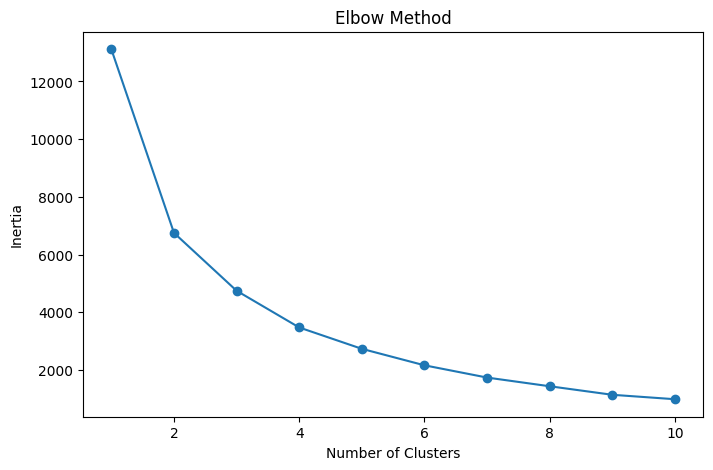

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1,11), inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

customer_df["Cluster"] = kmeans.fit_predict(X_scaled)

customer_df.head()

,Total_Spend,Number_of_Purchases,Total_Items,Cluster
CustomerID,,,,
12346.0,0.00,2,0,0
12347.0,4310.00,7,2458,0
12348.0,1797.24,4,2341,0
12349.0,1757.55,1,631,0
12350.0,334.40,1,197,0


In [ ]:
# Average values for each cluster

cluster_summary = customer_df.groupby("Cluster").mean()

cluster_summary

,Total_Spend,Number_of_Purchases,Total_Items
Cluster,,,
0,921.860531,3.243841,562.685772
1,47483.389091,75.136364,31949.818182
2,7107.799210,19.523161,4036.337875
3,195941.550000,93.600000,96858.400000


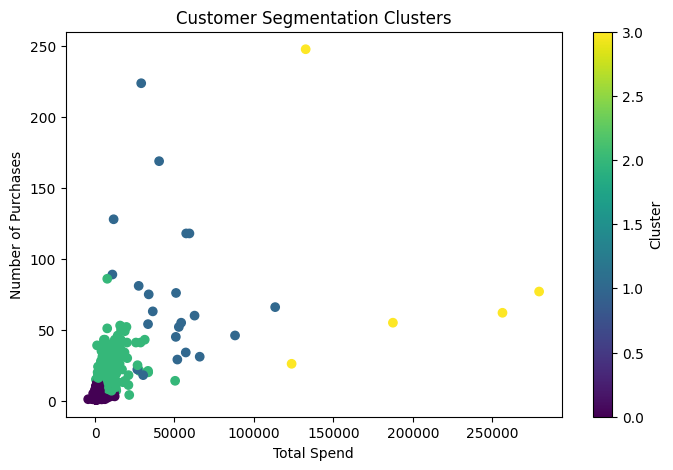

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(
    customer_df["Total_Spend"],
    customer_df["Number_of_Purchases"],
    c=customer_df["Cluster"],
    cmap="viridis"
)

plt.xlabel("Total Spend")
plt.ylabel("Number of Purchases")
plt.title("Customer Segmentation Clusters")
plt.colorbar(label="Cluster")

plt.show()

In [ ]:
import joblib

# Save model and scaler
joblib.dump(kmeans, "customer_segmentation_model.pkl")
joblib.dump(scaler, "customer_segmentation_scaler.pkl")

print("Models saved successfully!")

Models saved successfully!


In [ ]:
# # Customer Segmentation Using K-Means Clustering

# ## Problem Statement
# The goal of this project is to group customers into different segments based on their purchasing behavior using unsupervised machine learning.

# ## Dataset
# The dataset contains retail transaction records including:
# - Customer ID
# - Purchase quantity
# - Product price
# - Invoice information
# - Country

# ## Data Processing
# - Removed missing customer IDs
# - Created customer-level features:
#   - Total Spending
#   - Number of Purchases
#   - Total Items Purchased
# - Scaled features before clustering

# ## Algorithm Used
# - K-Means Clustering

# ## Number of Clusters
# Four customer segments were created.

# ## Customer Segments
# - Cluster 0: Low-value customers
# - Cluster 1: Loyal high-value customers
# - Cluster 2: Regular customers
# - Cluster 3: Premium/VIP customers

# ## Conclusion
# The model successfully grouped customers into meaningful segments based on purchasing behavior. This type of analysis can help businesses create targeted marketing strategies.